In [1]:
import pandas as pd
import numpy as np
import os

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
example_replay = '/Users/marcomaluf/Desktop/Unfinished Projects/paper/training_replays_csvs/2025-01-10.15.41 Millsy Ranked Standard Win.csv'
replay_df = pd.read_csv(example_replay).drop(columns='Unnamed: 0')
replay_df

,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,hit_team_no,pos_x.1,pos_y.1,pos_z.1,...,pos_y.6,pos_z.6,vel_x.6,vel_y.6,vel_z.6,boost_active.5,team.5,dist_to_ball.5,label,base_df_index
0,-2150.14,2238.17,1281.83,0.0,0.0,0.0,-1.0,-2451.20,2108.84,936.27,...,3471.75,17.01,0.0,0.0,2.7,False,1,2882.177461,0,847
1,-2121.76,2260.65,1265.37,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2906.257972,0,848
2,-2093.41,2283.11,1248.21,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2866.398167,0,849
3,-2072.17,2299.94,1234.88,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2836.333383,0,850
4,-2029.73,2333.56,1207.03,0.0,0.0,0.0,-1.0,-2258.31,2244.73,921.12,...,3902.20,17.01,0.0,0.0,2.7,False,1,2847.149314,0,851
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,9503.8,12213.9,4409.0,0.0,216.49,-3691.70,79.69,...,-4806.78,16.99,1901.8,-11020.5,7351.7,True,1,1041.306807,1,12825
1084,513.08,-5215.44,151.18,9488.9,12195.3,4077.2,0.0,216.49,-3691.70,79.69,...,-4816.89,16.99,1858.6,-10943.9,7195.9,False,1,881.296669,1,12826
1085,513.08,-5215.44,151.18,9481.7,12186.0,3911.6,0.0,400.41,-3786.63,79.53,...,-4818.54,16.99,1857.9,-10940.3,7096.8,False,1,854.023022,1,12827
1086,513.08,-5215.44,151.18,9472.1,12173.6,3690.8,0.0,400.41,-3786.63,79.53,...,-4818.54,16.99,1857.9,-10940.3,7096.8,False,1,854.023022,1,12828


In [3]:
positions_idx = [0,1,2,7,8,9,16,17,18,25,26,27,34,35,36,43,44,45,52,53,54]
replay_df.iloc[:,positions_idx]

,pos_x,pos_y,pos_z,pos_x.1,pos_y.1,pos_z.1,pos_x.2,pos_y.2,pos_z.2,pos_x.3,...,pos_z.3,pos_x.4,pos_y.4,pos_z.4,pos_x.5,pos_y.5,pos_z.5,pos_x.6,pos_y.6,pos_z.6
0,-2150.14,2238.17,1281.83,-2451.20,2108.84,936.27,-2392.10,-365.62,17.00,-668.06,...,17.01,-1987.33,4654.83,817.15,-62.99,-1031.62,56.95,127.02,3471.75,17.01
1,-2121.76,2260.65,1265.37,-2357.67,2176.82,928.22,-2392.10,-365.62,17.00,-668.06,...,17.01,-1925.60,4569.06,849.22,-74.78,-862.33,77.96,91.07,3671.79,17.01
2,-2093.41,2283.11,1248.21,-2357.67,2176.82,928.22,-2342.30,-225.74,17.00,-612.03,...,17.01,-1925.60,4569.06,849.22,-74.78,-862.33,77.96,91.07,3671.79,17.01
3,-2072.17,2299.94,1234.88,-2357.67,2176.82,928.22,-2342.30,-225.74,17.00,-612.03,...,17.01,-1884.28,4510.38,866.15,-74.78,-862.33,77.96,91.07,3671.79,17.01
4,-2029.73,2333.56,1207.03,-2258.31,2244.73,921.12,-2342.30,-225.74,17.00,-566.92,...,17.01,-1884.28,4510.38,866.15,-84.01,-685.34,81.96,26.84,3902.20,17.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,216.49,-3691.70,79.69,-2376.49,-4774.70,16.99,451.16,...,234.85,-232.45,815.16,87.48,752.86,-3443.52,79.47,-397.68,-4806.78,16.99
1084,513.08,-5215.44,151.18,216.49,-3691.70,79.69,-2260.80,-4793.29,16.99,611.21,...,232.88,-232.45,815.16,87.48,752.86,-3443.52,79.47,-261.41,-4816.89,16.99
1085,513.08,-5215.44,151.18,400.41,-3786.63,79.53,-2260.80,-4793.29,16.99,611.21,...,232.88,-367.06,720.06,86.38,915.57,-3500.76,75.49,-231.11,-4818.54,16.99
1086,513.08,-5215.44,151.18,400.41,-3786.63,79.53,-2176.14,-4807.47,16.99,700.77,...,288.37,-367.06,720.06,86.38,915.57,-3500.76,75.49,-231.11,-4818.54,16.99


In [4]:
replay_df.iloc[:,positions_idx].corr()

,pos_x,pos_y,pos_z,pos_x.1,pos_y.1,pos_z.1,pos_x.2,pos_y.2,pos_z.2,pos_x.3,...,pos_z.3,pos_x.4,pos_y.4,pos_z.4,pos_x.5,pos_y.5,pos_z.5,pos_x.6,pos_y.6,pos_z.6
pos_x,1.000000,-0.207729,0.112145,0.695727,-0.168633,-0.150178,0.531184,-0.198567,-0.483185,0.609520,...,0.405132,-0.064114,-0.068137,-0.069786,0.095667,0.086635,0.090209,0.590857,-0.094646,-0.079522
pos_y,-0.207729,1.000000,-0.117713,-0.206870,0.879545,0.453666,0.131120,0.786296,0.063295,-0.240469,...,-0.293543,-0.283262,-0.275556,-0.279526,-0.162027,-0.147148,-0.158865,-0.028940,0.741987,0.295235
pos_z,0.112145,-0.117713,1.000000,0.261378,-0.105040,0.431474,-0.103248,0.103896,0.121623,0.276552,...,-0.055017,0.222909,0.219816,0.220867,0.076514,0.073884,0.073670,0.011473,0.088783,0.281534
pos_x.1,0.695727,-0.206870,0.261378,1.000000,-0.164181,-0.034673,0.275384,-0.037851,-0.192519,0.245065,...,0.082321,-0.185939,-0.190457,-0.188746,0.039133,0.028655,0.033201,0.433664,0.065358,-0.092918
pos_y.1,-0.168633,0.879545,-0.105040,-0.164181,1.000000,0.598460,0.037641,0.720349,-0.005292,-0.156144,...,-0.200299,-0.307079,-0.300278,-0.305460,-0.149799,-0.134824,-0.146031,0.022212,0.682838,0.213351
pos_z.1,-0.150178,0.453666,0.431474,-0.034673,0.598460,1.000000,-0.306868,0.500187,0.008562,0.127812,...,-0.216190,0.086105,0.089211,0.086259,0.062961,0.072051,0.065062,-0.003781,0.401432,0.513182
pos_x.2,0.531184,0.131120,-0.103248,0.275384,0.037641,-0.306868,1.000000,-0.035006,-0.271237,0.175061,...,-0.076857,-0.287206,-0.287331,-0.290197,0.010946,0.004871,0.004374,0.187236,0.055049,-0.091719
pos_y.2,-0.198567,0.786296,0.103896,-0.037851,0.720349,0.500187,-0.035006,1.000000,0.180494,-0.424030,...,-0.377748,-0.429993,-0.426692,-0.427706,-0.220113,-0.208527,-0.217039,-0.066527,0.644663,0.220414
pos_z.2,-0.483185,0.063295,0.121623,-0.192519,-0.005292,0.008562,-0.271237,0.180494,1.000000,-0.321965,...,-0.233555,0.096503,0.096759,0.097790,-0.415319,-0.411276,-0.413632,-0.335252,0.113016,-0.011213
pos_x.3,0.609520,-0.240469,0.276552,0.245065,-0.156144,0.127812,0.175061,-0.424030,-0.321965,1.000000,...,0.438340,0.446751,0.445056,0.442360,0.336160,0.333460,0.332965,0.308120,-0.235282,0.169833


In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = replay_df.iloc[:,positions_idx]

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i) for i in range(X.shape[1])
]

print(vif_data)

    feature            VIF
0     pos_x      12.247354
1     pos_y      38.957279
2     pos_z      12.931176
3   pos_x.1       6.044720
4   pos_y.1      17.445727
5   pos_z.1      10.818117
6   pos_x.2      10.924015
7   pos_y.2      10.594950
8   pos_z.2       3.921200
9   pos_x.3      16.063143
10  pos_y.3       8.755216
11  pos_z.3       4.176952
12  pos_x.4   96432.392637
13  pos_y.4   68993.493376
14  pos_z.4  162448.902410
15  pos_x.5   74352.641226
16  pos_y.5   81606.975712
17  pos_z.5  261011.463139
18  pos_x.6       7.614269
19  pos_y.6       9.451421
20  pos_z.6       8.127260


In [6]:
replay_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1088 entries, 0 to 1087
Data columns (total 63 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pos_x           1088 non-null   float64
 1   pos_y           1088 non-null   float64
 2   pos_z           1088 non-null   float64
 3   vel_x           1088 non-null   float64
 4   vel_y           1088 non-null   float64
 5   vel_z           1088 non-null   float64
 6   hit_team_no     1088 non-null   float64
 7   pos_x.1         1088 non-null   float64
 8   pos_y.1         1088 non-null   float64
 9   pos_z.1         1088 non-null   float64
 10  vel_x.1         1088 non-null   float64
 11  vel_y.1         1088 non-null   float64
 12  vel_z.1         1088 non-null   float64
 13  boost_active    1088 non-null   bool   
 14  team            1088 non-null   int64  
 15  dist_to_ball    1088 non-null   float64
 16  pos_x.2         1088 non-null   float64
 17  pos_y.2         1088 non-null   float64
 18 

In [7]:
import matplotlib.pyplot as plt

random_time = np.random.randint(low=0,high=1088)
random_time

6

In [8]:
positions = replay_df.iloc[random_time, positions_idx]
positions

pos_x     -2008.54
pos_y      2350.36
pos_z      1192.51
pos_x.1   -2193.77
pos_y.1    2287.99
pos_z.1     914.87
pos_x.2   -2261.97
pos_y.2     -93.13
pos_z.2      17.00
pos_x.3    -557.08
pos_y.3    1982.31
pos_z.3      17.01
pos_x.4   -1828.60
pos_y.4    4430.57
pos_z.4     883.16
pos_x.5     -84.01
pos_y.5    -685.34
pos_z.5      81.96
pos_x.6      26.84
pos_y.6    3902.20
pos_z.6      17.01
Name: 6, dtype: float64

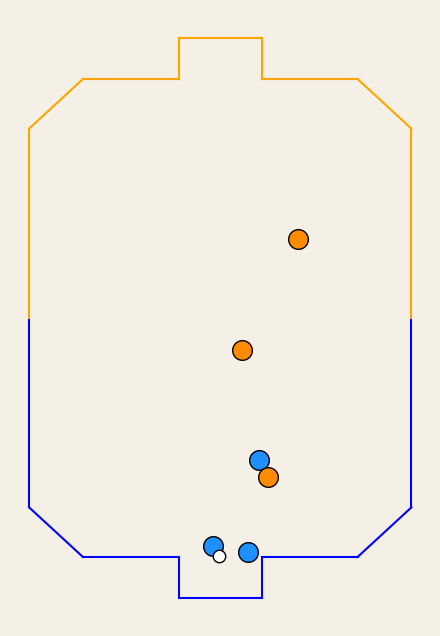

In [12]:
import matplotlib.pyplot as plt

random_time = np.random.randint(low=0,high=1088)

positions = replay_df.iloc[random_time, positions_idx]

LINES = [   # blue half
            [(4096,0),(4096,-4058)],
            [(-2944,-5120),(-893,-5120)],
            [(2944,-5120),(893,-5120)],
            [(-4096,0),(-4096,-4058)],
            [(2944,-5120),(4096,-4058)],
            [(-2944,-5120),(-4096,-4058)],
            [(893,-6000),(-893,-6000)],
            [(893,-6000),(893,-5120)],
            [(-893,-6000),(-893,-5120)],
            # orange half
            [(4096,0),(4096,4058)],
            [(-2944,5120),(-893,5120)],
            [(2944,5120),(893,5120)],
            [(-4096,0),(-4096,4058)],
            [(2944,5120),(4096,4058)],
            [(-2944,5120),(-4096,4058)],
            [(893,6000),(-893,6000)],
            [(893,6000),(893,5120)],
            [(-893,6000),(-893,5120)],
        ]

COLORS = ['blue']*9 + ['orange']*9


def draw_field(ax=None, figsize=(12, 8), linewidth=1.5):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for line, color in zip(LINES, COLORS):
        xs = [line[0][0], line[1][0]]
        ys = [line[0][1], line[1][1]]
        ax.plot(xs, ys, color=color, linewidth=linewidth, zorder=1)
    ax.set_aspect('equal')
    ax.figure.set_facecolor("#F5F0E6")
    ax.axis('off')
    ax.set_facecolor('none')
    return ax


def plot_positions(
    frame: pd.Series,
    ax=None,
    ball_color="white",
    ball_size=80,
    blue_color="dodgerblue",
    orange_color="darkorange",
    player_size=200,
    figsize=(12, 8),
):
    """
    Overlay a single time slice onto the field.

    frame: pd.Series with pos_x/pos_y/pos_z for the ball, followed by
           pos_x.1..pos_z.1, ... for each player.
           Suffixes 1-3 = blue team, 4-6 = orange team.
    """
    if ax is None:
        ax = draw_field(figsize=figsize)

    suffixes = sorted(
        {c[len("pos_x"):] for c in frame.index if c.startswith("pos_x")},
        key=lambda s: int(s.lstrip(".")) if s else -1,
    )

    for suf in suffixes:
        x, y = frame[f"pos_x{suf}"], frame[f"pos_y{suf}"]
        if suf == "":  # ball
            ax.scatter(x, y, c=ball_color, s=ball_size,
                       edgecolors="black", zorder=3)
        else:
            idx = int(suf.lstrip("."))
            color = blue_color if idx <= 3 else orange_color
            ax.scatter(x, y, c=color, s=player_size,
                       edgecolors="black", zorder=2)

    return ax

plot_positions(positions)
plt.show()

In [13]:
random_time

827

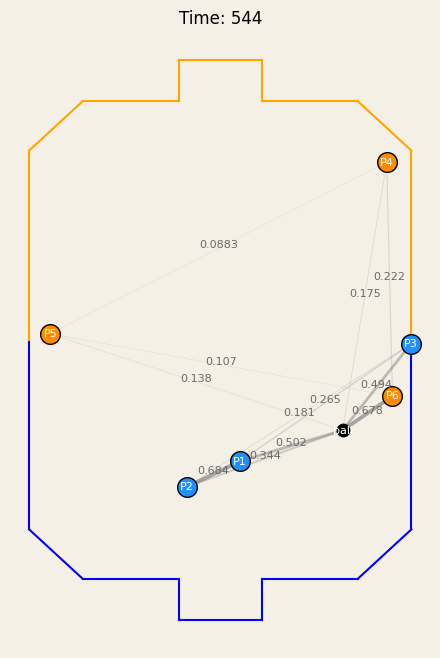

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# random_time = np.random.randint(low=0,high=1088)

positions = replay_df.iloc[544, positions_idx]

SIGMA = 0.0003

def parse_frame(frame: pd.Series):
    """Return [(label, team, x, y), ...] for the ball and each player."""
    suffixes = sorted(
        {c[len("pos_x"):] for c in frame.index if c.startswith("pos_x")},
        key=lambda s: int(s.lstrip(".")) if s else -1,
    )
    nodes = []
    for suf in suffixes:
        x, y = float(frame[f"pos_x{suf}"]), float(frame[f"pos_y{suf}"])
        if suf == "":
            nodes.append(("ball", "ball", x, y))
        else:
            idx = int(suf.lstrip("."))
            team = "blue" if idx <= 3 else "orange"
            nodes.append((f"P{idx}", team, x, y))
    return nodes


def build_graph(frame: pd.Series, sigma: float = SIGMA):
    """
    Undirected weighted graph: ball connects to every player,
    players connect only to same-team players.
    Weight = exp(-d^2 / (2 * sigma^2)).
    """
    nodes = parse_frame(frame)
    edges = []
    for i in range(len(nodes)):
        for j in range(i + 1, len(nodes)):
            li, ti, xi, yi = nodes[i]
            lj, tj, xj, yj = nodes[j]
            if not (ti == "ball" or tj == "ball" or ti == tj):
                continue
            d = np.hypot(xi - xj, yi - yj)
            # w = np.exp(-(d ** 2) / (2 * sigma ** 2))
            w = np.exp(-sigma * d)
            edges.append((i, j, w))
    return nodes, edges


def plot_graph(
    frame: pd.Series,
    ax=None,
    sigma: float = SIGMA,
    ball_color="black",
    ball_size=80,
    blue_color="dodgerblue",
    orange_color="darkorange",
    player_size=200,
    edge_color="gray",
    max_edge_width=4.0,
    show_weights=True,
    figsize=(12, 8),
):
    if ax is None:
        ax = draw_field(figsize=figsize)

    nodes, edges = build_graph(frame, sigma)

    for i, j, w in edges:
        _, _, xi, yi = nodes[i]
        _, _, xj, yj = nodes[j]
        ax.plot([xi, xj], [yi, yj], color=edge_color,
                linewidth=max(w * max_edge_width, 0.4),
                alpha=max(w, 0.15), zorder=2)
        if show_weights:
            ax.annotate(f"{w:.3g}", ((xi + xj) / 2, (yi + yj) / 2),
                        fontsize=8, color="dimgray", ha="center", zorder=4)

    for label, team, x, y in nodes:
        if team == "ball":
            c, s = ball_color, ball_size
        else:
            c = blue_color if team == "blue" else orange_color
            s = player_size
        ax.scatter(x, y, c=c, s=s, edgecolors="black", zorder=3)
        ax.annotate(label, (x, y), fontsize=8, ha="center", va="center",
                    color="white", zorder=5)

    return ax, nodes, edges

plot_graph(positions)
plt.title(f'Time: {544}')
plt.show()

Good-looking times: 344, 363, 544, 774